In [1]:
!pip -q install torch numpy pandas matplotlib

In [2]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from copy import deepcopy

np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(2)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

Urządzenie: cpu


Źródło: Open-Meteo ERA5, Lublin, średnia temperatura dobowa
Zakres: 2020-01-01 - 2025-12-31 Dni: 2192
Trening: 1534 Walidacja: 329 Test: 329


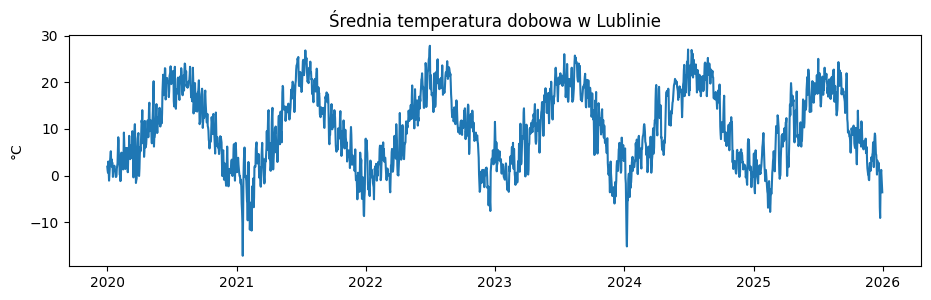

In [3]:
import json
import urllib.parse
import urllib.request

params = {
    'latitude': 51.25,
    'longitude': 22.57,
    'start_date': '2020-01-01',
    'end_date': '2025-12-31',
    'daily': 'temperature_2m_mean',
    'timezone': 'Europe/Warsaw',
    'models': 'era5'
}
url = 'https://archive-api.open-meteo.com/v1/archive?' + urllib.parse.urlencode(params)
with urllib.request.urlopen(url, timeout=60) as response:
    dane = json.loads(response.read().decode('utf-8'))
daty = pd.to_datetime(dane['daily']['time'])
serie = pd.Series(dane['daily']['temperature_2m_mean'], index=daty, dtype=float)
if serie.isna().any():
    raise ValueError('W danych pogodowych są braki: ' + str(serie.isna().sum()))
seria = serie.to_numpy(dtype=np.float32)
n = len(seria)
i_tr = int(0.7 * n)
i_va = int(0.85 * n)
mu = float(seria[:i_tr].mean())
sd = float(seria[:i_tr].std())
s = (seria - mu) / sd
print('Źródło: Open-Meteo ERA5, Lublin, średnia temperatura dobowa')
print('Zakres:', daty[0].date(), '-', daty[-1].date(), 'Dni:', n)
print('Trening:', i_tr, 'Walidacja:', i_va - i_tr, 'Test:', n - i_va)
plt.figure(figsize=(11, 3))
plt.plot(daty, seria)
plt.title('Średnia temperatura dobowa w Lublinie')
plt.ylabel('°C')
plt.show()

In [4]:
def zrob_okna(s, okno, start, koniec):
    x = np.stack([s[t-okno:t] for t in range(max(okno, start), koniec)]).astype(np.float32)
    y = np.array([s[t] for t in range(max(okno, start), koniec)], dtype=np.float32)
    return torch.tensor(x[..., None], device=DEVICE), torch.tensor(y[:, None], device=DEVICE)

class ModelGRU(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.GRU(1, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

def trenuj(okno, seed, epoki=40):
    torch.manual_seed(seed)
    xtr, ytr = zrob_okna(s, okno, okno, i_tr)
    xva, yva = zrob_okna(s, okno, i_tr, i_va)
    model = ModelGRU(32).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=0.01)
    loss = nn.MSELoss()
    historia = []
    best = float('inf')
    best_epoch = 0
    best_state = None
    for ep in range(epoki):
        model.train()
        order = torch.randperm(len(xtr), device=DEVICE)
        for j in range(0, len(xtr), 64):
            idx = order[j:j+64]
            opt.zero_grad()
            loss(model(xtr[idx]), ytr[idx]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            ltr = loss(model(xtr), ytr).item()
            lva = loss(model(xva), yva).item()
        historia.append((ltr, lva))
        if lva < best:
            best = lva
            best_epoch = ep + 1
            best_state = deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return model, np.array(historia), best, best_epoch

def mae(a, b):
    return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))

def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b))**2)))

def test_jednokrokowy(model, okno):
    xte, yte = zrob_okna(s, okno, i_va, n)
    model.eval()
    with torch.no_grad():
        p = model(xte).cpu().numpy().ravel() * sd + mu
    return p, yte.cpu().numpy().ravel() * sd + mu

def test_wielokrokowy(model, okno, H=14):
    starty = np.arange(i_va, n-H+1, H)
    prawda = np.stack([seria[t:t+H] for t in starty])
    prognozy = []
    model.eval()
    for t in starty:
        hist = list(s[t-okno:t])
        out = []
        for h in range(H):
            x = torch.tensor(np.array(hist[-okno:], dtype=np.float32).reshape(1, okno, 1), device=DEVICE)
            with torch.no_grad():
                nxt = float(model(x).item())
            out.append(nxt * sd + mu)
            hist.append(nxt)
        prognozy.append(out)
    prognozy = np.array(prognozy)
    naiwny = np.stack([np.repeat(seria[t-1], H) for t in starty])
    sezonowy = np.stack([np.tile(seria[t-7:t], 2)[:H] for t in starty])
    return prawda, prognozy, naiwny, sezonowy, starty

Najlepsza epoka: 5 Walidacyjne MSE: 0.0653


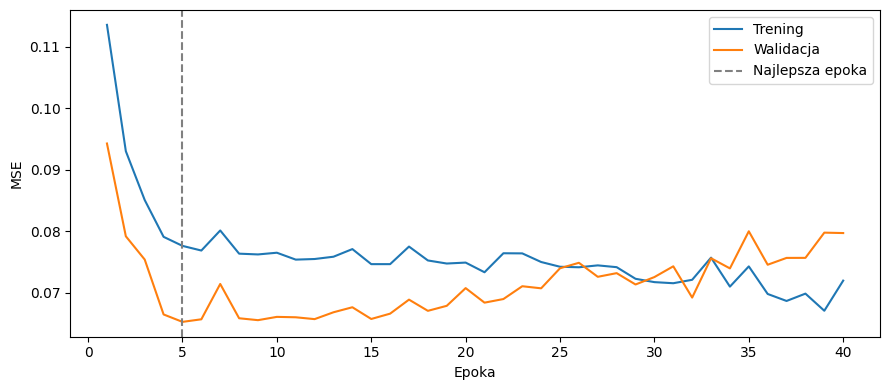

In [5]:
OKNO = 28
model, hist, best_val, best_epoch = trenuj(OKNO, 0)
print('Najlepsza epoka:', best_epoch, 'Walidacyjne MSE:', round(best_val, 5))
plt.figure(figsize=(9, 4))
plt.plot(np.arange(1, len(hist)+1), hist[:, 0], label='Trening')
plt.plot(np.arange(1, len(hist)+1), hist[:, 1], label='Walidacja')
plt.axvline(best_epoch, color='gray', linestyle='--', label='Najlepsza epoka')
plt.xlabel('Epoka')
plt.ylabel('MSE')
plt.legend()
plt.tight_layout()
plt.show()

,Metoda,MAE 1 dzień,RMSE 1 dzień,MAE 14 dni,RMSE 14 dni
0,GRU,1.692,2.160,3.280,4.188
1,Naiwny,1.788,2.290,3.557,4.367
2,Sezonowy,3.960,5.025,4.125,5.092


Starty prognoz: [1863, 1877, 1891, 1905, 1919, 1933, 1947, 1961, 1975, 1989, 2003, 2017, 2031, 2045, 2059, 2073, 2087, 2101, 2115, 2129, 2143, 2157, 2171]


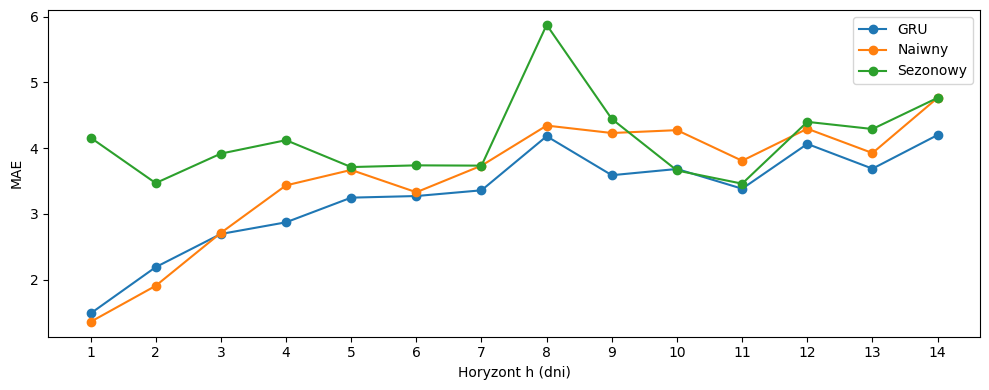

In [6]:
pred1, true1 = test_jednokrokowy(model, OKNO)
tgt = np.arange(i_va, n)
base_naiwny = seria[tgt-1]
base_sezonowy = seria[tgt-7]
true14, pred14, base14_naiwny, base14_sezonowy, starty = test_wielokrokowy(model, OKNO)
wyniki = pd.DataFrame([
    ['GRU', mae(true1, pred1), rmse(true1, pred1), mae(true14, pred14), rmse(true14, pred14)],
    ['Naiwny', mae(true1, base_naiwny), rmse(true1, base_naiwny), mae(true14, base14_naiwny), rmse(true14, base14_naiwny)],
    ['Sezonowy', mae(true1, base_sezonowy), rmse(true1, base_sezonowy), mae(true14, base14_sezonowy), rmse(true14, base14_sezonowy)]
], columns=['Metoda', 'MAE 1 dzień', 'RMSE 1 dzień', 'MAE 14 dni', 'RMSE 14 dni'])
display(wyniki.round(3))
print('Starty prognoz:', starty.tolist())
plt.figure(figsize=(10, 4))
for name, forecast in [('GRU', pred14), ('Naiwny', base14_naiwny), ('Sezonowy', base14_sezonowy)]:
    plt.plot(np.arange(1, 15), np.mean(np.abs(true14 - forecast), axis=0), marker='o', label=name)
plt.xlabel('Horyzont h (dni)')
plt.ylabel('MAE')
plt.xticks(np.arange(1, 15))
plt.legend()
plt.tight_layout()
plt.show()

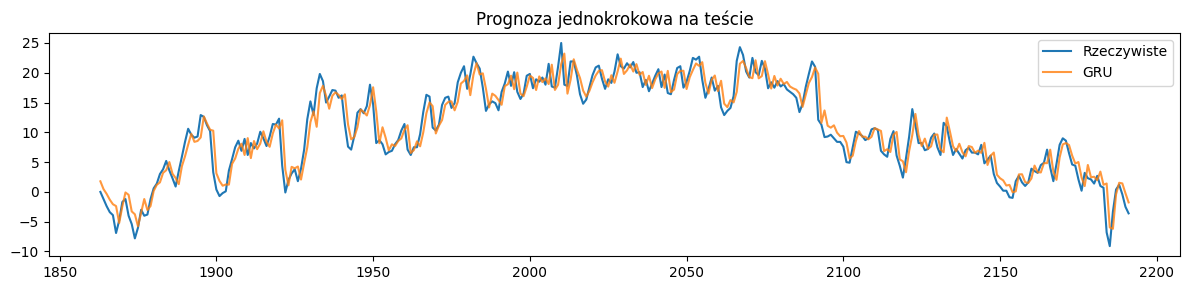

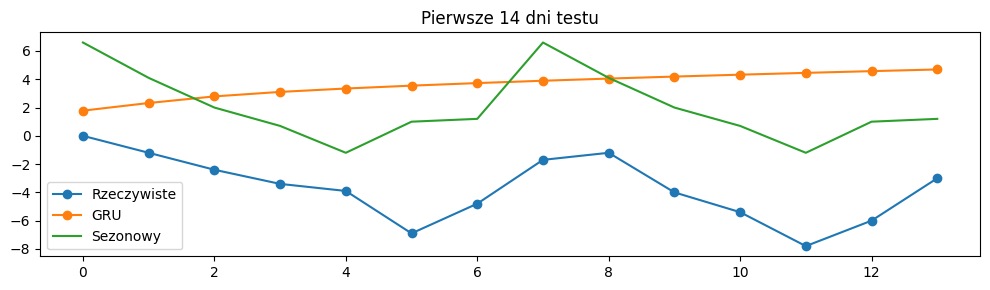

In [7]:
plt.figure(figsize=(12, 3))
plt.plot(tgt, true1, label='Rzeczywiste')
plt.plot(tgt, pred1, label='GRU', alpha=0.8)
plt.title('Prognoza jednokrokowa na teście')
plt.legend()
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 3))
plt.plot(np.arange(14), true14[0], marker='o', label='Rzeczywiste')
plt.plot(np.arange(14), pred14[0], marker='o', label='GRU')
plt.plot(np.arange(14), base14_sezonowy[0], label='Sezonowy')
plt.legend()
plt.title('Pierwsze 14 dni testu')
plt.tight_layout()
plt.show()

In [8]:
rekordy = []
for okno in [3, 7, 28]:
    for seed in [0, 1]:
        m, history, v, ep = trenuj(okno, seed)
        p, y = test_jednokrokowy(m, okno)
        y14, p14, _, _, _ = test_wielokrokowy(m, okno)
        rekordy.append([okno, seed, ep, v, mae(y, p), mae(y14, p14)])
        print('OKNO:', okno, 'seed:', seed, 'epoka:', ep, 'val:', round(v, 5))
eksperymenty = pd.DataFrame(rekordy, columns=['OKNO', 'seed', 'Najlepsza epoka', 'Walidacyjne MSE', 'MAE 1 dzień', 'MAE 14 dni'])
display(eksperymenty.round(4))
podsumowanie = eksperymenty.groupby('OKNO')[['Walidacyjne MSE', 'MAE 1 dzień', 'MAE 14 dni']].agg(['mean', 'std'])
display(podsumowanie.round(4))
najlepsze_okno = int(eksperymenty.groupby('OKNO')['Walidacyjne MSE'].mean().idxmin())
print('Najlepsze okno według walidacji:', najlepsze_okno)
print('GRU MAE dla danych pogodowych:', round(mae(true1, pred1), 3), '°C')

OKNO: 3 seed: 0 epoka: 39 val: 0.06519
OKNO: 3 seed: 1 epoka: 16 val: 0.06541
OKNO: 7 seed: 0 epoka: 11 val: 0.06596
OKNO: 7 seed: 1 epoka: 11 val: 0.06602
OKNO: 28 seed: 0 epoka: 5 val: 0.0653
OKNO: 28 seed: 1 epoka: 9 val: 0.06455


,OKNO,seed,Najlepsza epoka,Walidacyjne MSE,MAE 1 dzień,MAE 14 dni
0,3,0,39,0.0652,1.6829,3.2761
1,3,1,16,0.0654,1.6837,3.2757
2,7,0,11,0.0660,1.6834,3.2635
3,7,1,11,0.0660,1.6877,3.3047
4,28,0,5,0.0653,1.6915,3.2803
5,28,1,9,0.0645,1.6940,3.1366


Walidacyjne MSE         MAE 1 dzień         MAE 14 dni        
                mean     std        mean     std       mean     std
OKNO                                                               
3             0.0653  0.0002      1.6833  0.0006     3.2759  0.0003
7             0.0660  0.0000      1.6855  0.0031     3.2841  0.0291
28            0.0649  0.0005      1.6928  0.0018     3.2084  0.1017

Najlepsze okno według walidacji: 28
GRU MAE dla danych pogodowych: 1.692 °C
